In [15]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input,Flatten

In [16]:
train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")
x_train = train_data.drop("label",axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label",axis=1).values
y_test = test_data["label"].values
# (x_train,y_train),(x_test,y_test) = keras.datasets.mnist.load_data();

print("Training data shape:",x_train.shape)
print("Testing data shape:",x_test.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [17]:
x_train = x_train.astype("float32")/255.0;
x_test = x_test.astype("float32")/255.0;

In [18]:
model = Sequential([
    Input(shape=(784,)),
    Flatten(),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer="SGD",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1,
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8207 - loss: 0.6745 - val_accuracy: 0.9210 - val_loss: 0.2811
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9124 - loss: 0.3086 - val_accuracy: 0.9352 - val_loss: 0.2267
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9260 - loss: 0.2566 - val_accuracy: 0.9460 - val_loss: 0.1942
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9369 - loss: 0.2225 - val_accuracy: 0.9532 - val_loss: 0.1725
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9434 - loss: 0.1965 - val_accuracy: 0.9552 - val_loss: 0.1570
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9492 - loss: 0.1757 - val_accuracy: 0.9612 - val_loss: 0.1420
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9539 - loss: 0.1588 - val_accuracy: 0.9653 - val_loss: 0.1297
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9589 - loss: 0.

In [21]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("Test loss:",test_loss)
print("Accuracy:",test_accuracy*100,"%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9656 - loss: 0.1151
Test loss: 0.11508572101593018
Accuracy: 96.56000137329102 %


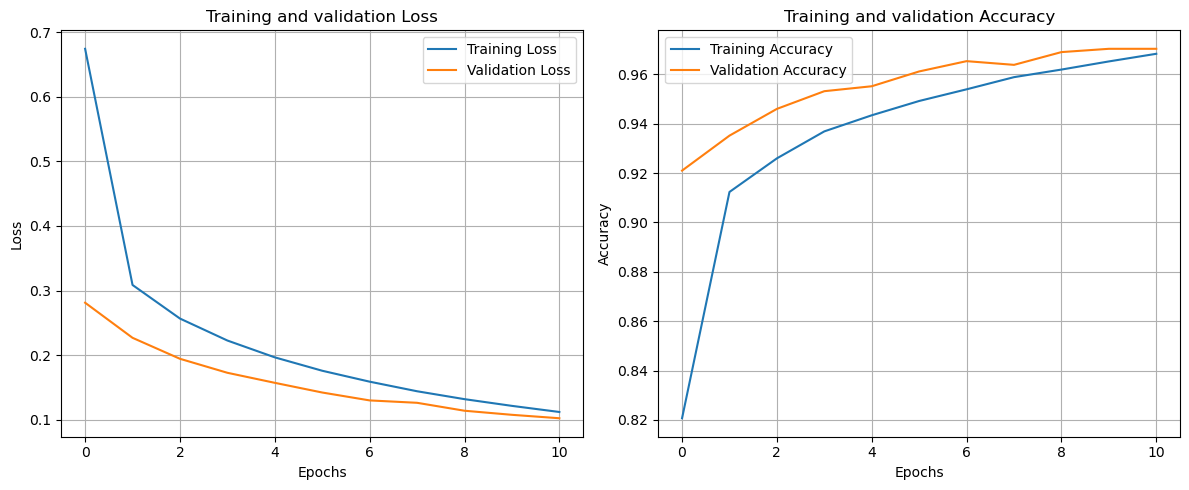

In [22]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.title("Training and validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("Training and validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input,Flatten

train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")
x_train = train_data.drop("label",axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label",axis=1).values
y_test = test_data["label"].values
# (x_train,y_train),(x_test,y_test) = keras.datasets.mnist.load_data();

print("Training data shape:",x_train.shape)
print("Testing data shape:",x_test.shape)

x_train = x_train.astype("float32")/255.0;
x_test = x_test.astype("float32")/255.0;

model = Sequential([
    Input(shape=(784,)),
    Flatten(),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])
model.summary()

model.compile(
    optimizer="SGD",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1,
)

test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("Test loss:",test_loss)
print("Accuracy:",test_accuracy*100,"%")

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.title("Training and validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("Training and validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
